# Exercise 26 – Dynamics of atoms on a surface

**Week 5 · Molecular dynamics**

Five atoms in a row are held fixed (a "surface", orange) and two mobile atoms
(blue) sit on top. After relaxing the structure we give the mobile atoms a
small random displacement and follow the motion with velocity Verlet. The
total energy should stay constant while kinetic and potential energy are
exchanged.

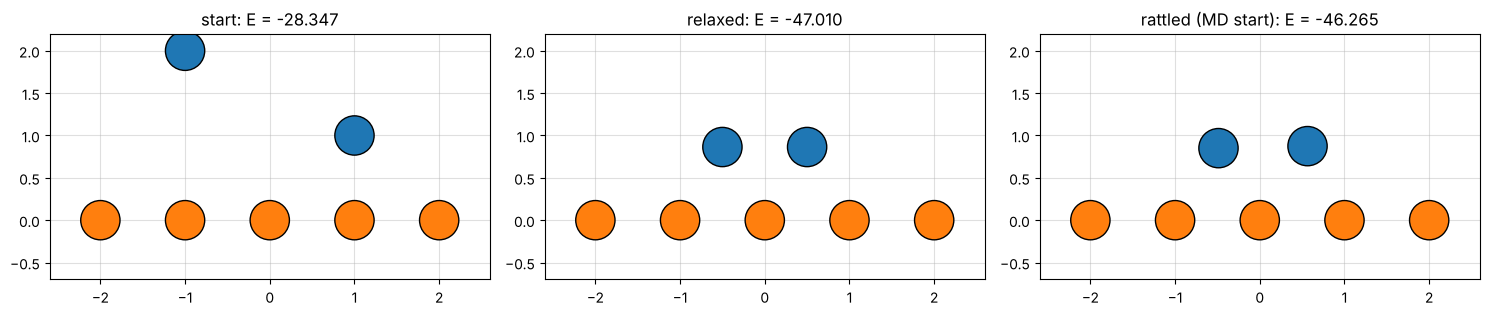

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image
from matplotlib.animation import FuncAnimation, PillowWriter

from comphy import ROOT_DIR
from comphy.atoms import Cluster, LennardJones, line_search_relax
from comphy.md import kinetic_energy, velocity_verlet

rng = np.random.default_rng(0)
calc = LennardJones()
start = [[-2, 0], [-1, 0], [0, 0], [1, 0], [2, 0], [-1, 2], [1, 1]]
cluster = Cluster(calc, start, static=[True] * 5 + [False] * 2)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cluster.draw(axes[0], size=800)
line_search_relax(cluster)
cluster.draw(axes[1], size=800)
cluster.positions[cluster.dynamic] += 0.1 * rng.normal(size=(2, 2))
cluster.draw(axes[2], size=800)
for ax, title in zip(axes, ["start", "relaxed", "rattled (MD start)"]):
    ax.set(xlim=(-2.6, 2.6), ylim=(-0.7, 2.2))
    ax.set_title(f"{title}: {ax.get_title()}")
    ax.grid(True, alpha=0.4)
fig.tight_layout()
plt.show()

## Running the dynamics

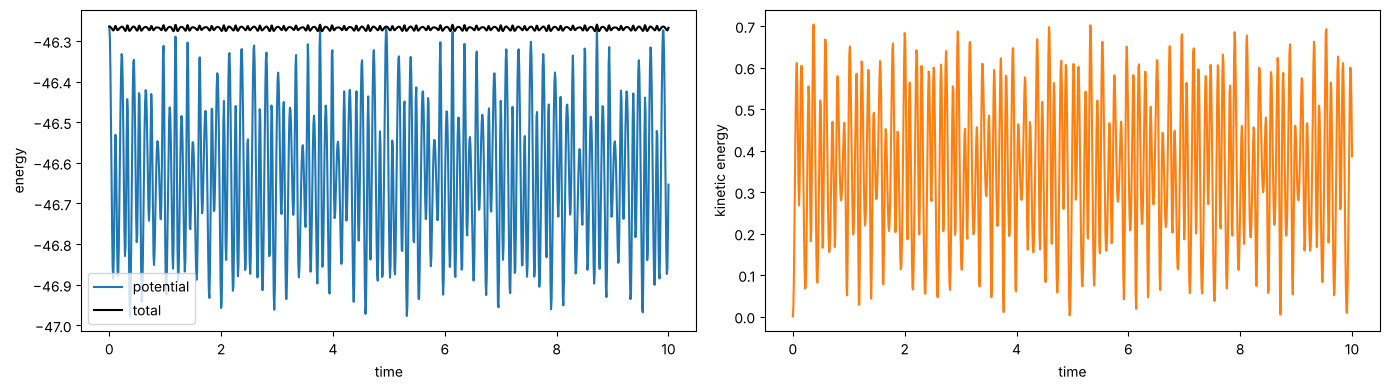

total energy drift over the run: 1.61e-02


In [2]:
xs, vs = velocity_verlet(cluster.positions, np.zeros_like(cluster.positions), cluster.calc.forces,
                         n_steps=1000, dt=0.01, fixed=cluster.static)
potential = np.array([calc.energy(x) for x in xs])
kinetic = np.array([kinetic_energy(v) for v in vs])
t = 0.01 * np.arange(len(xs))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(t, potential, label="potential")
axes[0].plot(t, potential + kinetic, label="total", color="black")
axes[0].set(xlabel="time", ylabel="energy")
axes[0].legend()
axes[1].plot(t, kinetic, color="C1")
axes[1].set(xlabel="time", ylabel="kinetic energy")
fig.tight_layout()
plt.show()
print(f"total energy drift over the run: {np.ptp(potential + kinetic):.2e}")

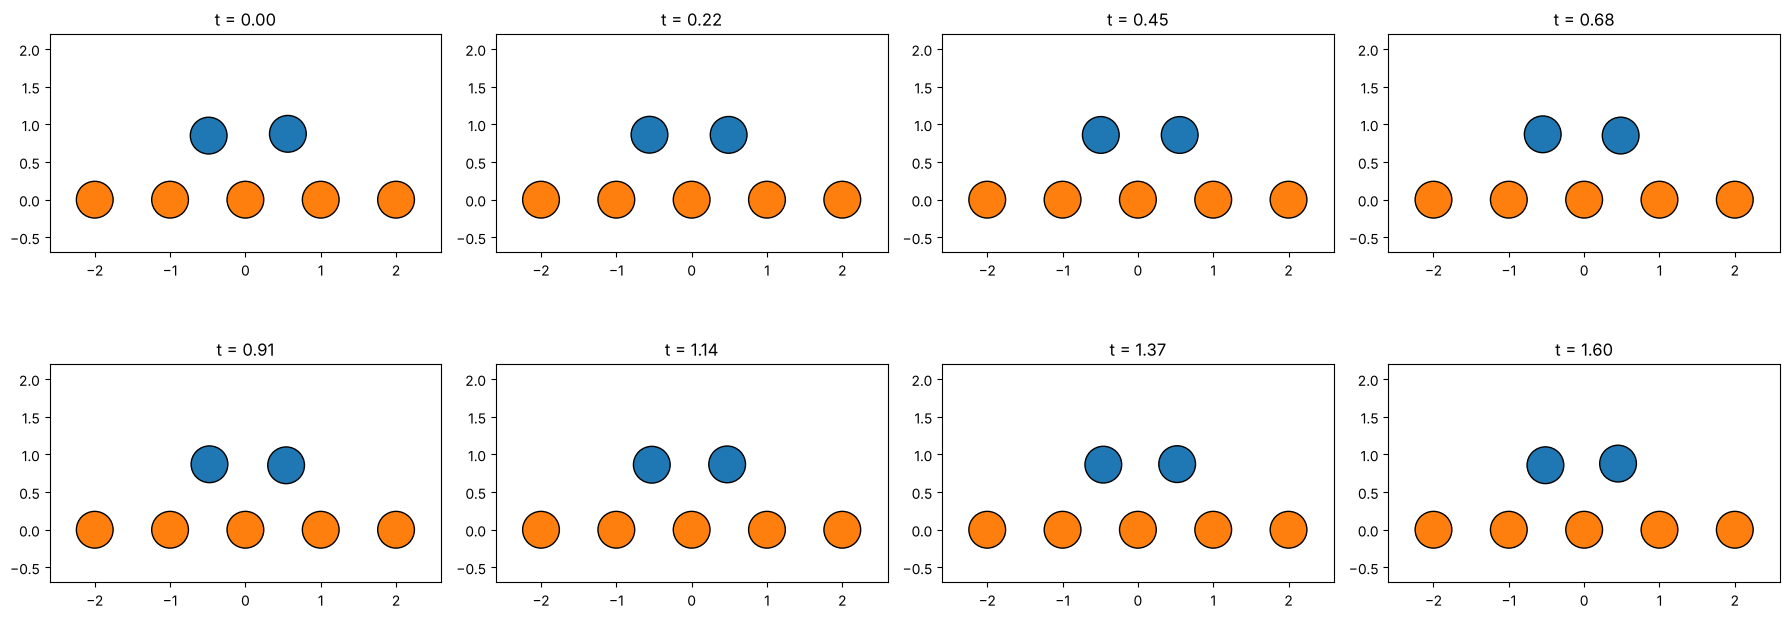

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, i in zip(axes.flat, np.linspace(0, 160, 8).astype(int)):
    Cluster(calc, xs[i], cluster.static).draw(ax, size=700, title=False)
    ax.set(xlim=(-2.6, 2.6), ylim=(-0.7, 2.2), title=f"t = {t[i]:.2f}")
fig.tight_layout()
plt.show()

## Animation

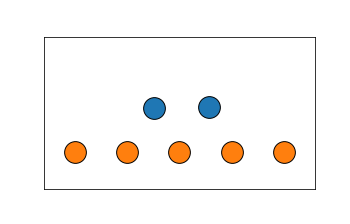

In [4]:
gif = ROOT_DIR / "figures" / "ex26_surface_dynamics.gif"
gif.parent.mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(5, 3.2), dpi=70)
ax.scatter(*xs[0][cluster.static].T, s=500, c="C1", edgecolor="black")
mobile = ax.scatter(*xs[0][~cluster.static].T, s=500, c="C0", edgecolor="black")
ax.set(xlim=(-2.6, 2.6), ylim=(-0.7, 2.2), aspect="equal", xticks=[], yticks=[])
frames = range(0, len(xs), 5)
anim = FuncAnimation(fig, lambda i: mobile.set_offsets(xs[i][~cluster.static]), frames=frames)
anim.save(gif, writer=PillowWriter(fps=25))
plt.close(fig)
Image(filename=gif)